<a href="https://colab.research.google.com/github/fralfaro/inf449-portafolio/blob/main/tareas/tarea-02/homework2.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


# Tarea 2: Neural Networks Driven by Physics and CNNs for RGB Demosaicking

## Objetivo de aprendizaje

Comprender e implementar el problema de demosaicking como una tarea de reconstruccion de imagenes RGB a partir de una medicion incompleta producida por un sensor con filtro Bayer. Se busca que el estudiante compare una solucion clasica basada en interpolacion con dos aproximaciones neuronales: una representacion neuronal implicita y una red neuronal convolucional.

Al finalizar la tarea, se espera que el estudiante pueda relacionar el modelo fisico de adquisicion del sensor con el diseño, entrenamiento y evaluacion de modelos de aprendizaje profundo, distinguiendo entre una evaluacion controlada con referencia RGB conocida y una captura RAW/DNG real.


## Enunciado

El objetivo de la tarea es reconstruir una imagen RGB a partir de una medicion mosaico capturada por un dispositivo electronico, como un telefono, tablet o camara digital. La medicion corresponde a una imagen RAW o DNG generada por un sensor cubierto con un arreglo de filtros de color Bayer.

A partir de esta medicion, se deben implementar y analizar algoritmos de demosaicking basados en:

1. Metodos tradicionales de interpolacion.
2. Representaciones neuronales implicitas.
3. Redes neuronales convolucionales.

Los resultados deben compararse cuantitativa y cualitativamente con una imagen RGB de referencia. Para la evaluacion controlada se utilizara una imagen RGB conocida, a partir de la cual se genera artificialmente el mosaico Bayer. Adicionalmente, se analizara una captura DNG real para verificar la aplicacion de los metodos en una medicion producida por un sensor.

El notebook debe documentar el procedimiento, visualizar la imagen original, la medicion Bayer y las reconstrucciones, reportar las metricas de calidad disponibles y discutir las ventajas y limitaciones de cada enfoque. La red convolucional debera entrenarse con imagenes de entrenamiento y evaluarse sobre imagenes no vistas.


## 1. Preparacion del entorno

En esta seccion se cargaran las librerias necesarias para trabajar con imagenes, arreglos numericos, visualizacion, metricas y entrenamiento de redes neuronales.

Las implementaciones finales deberian considerar, al menos:

- `numpy` para operaciones numericas.
- `matplotlib` para visualizacion.
- `Pillow` u `OpenCV` para lectura y procesamiento de imagenes.
- `torch` para definir y entrenar redes neuronales.
- `pandas` para organizar los resultados experimentales.


In [34]:
# Dependencias para Google Colab
# En Colab, torch suele venir instalado. Esta celda asegura el resto de paquetes usados en la tarea.
%pip install -q opencv-python scikit-image scipy pillow pandas matplotlib rawpy imageio

# Imports generales
from pathlib import Path
from collections import OrderedDict
import os
import time
import math
import urllib.request
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import cv2
from skimage import data
from skimage.transform import resize
from skimage.metrics import peak_signal_noise_ratio
from skimage.metrics import structural_similarity as ssim
from scipy.ndimage import correlate

try:
    import rawpy
except ImportError:
    rawpy = None

import torch
from torch import nn, optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset

# Configuracion compartida de la CNN. Se define al inicio para evitar que las
# celdas de entrenamiento fallen si se ejecutan individualmente.
CNN_BASE_CONFIG = {
    "input_channels": 4,
    "hidden_channels": 16,
    "num_blocks": 0,
    "epochs": 6,
    "learning_rate": 1e-3,
    "batch_size": 32,
    "physics_weight": 0.1,
}

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")


Device: cuda


## 2. Datos de trabajo

Para que la tarea sea justa y clara, se separan dos tipos de experimento:

1. **Experimento controlado con referencia conocida**: se usa una imagen RGB (`demo.jpg`) como referencia, se genera un mosaico Bayer sintetico y se evaluan las reconstrucciones con MSE, PSNR y SSIM. Esta es la parte adecuada para comparar metodos de forma cuantitativa, porque se conoce la imagen RGB antes del mosaico.
2. **Experimento real RAW/DNG**: se usa `demo.dng` para leer una medicion real del sensor, detectar el patron CFA/Bayer y visualizar un revelado basico. En esta parte `demo.jpg` se usa solo como referencia visual aproximada, porque ya fue procesada por la camara.

Esta separacion es importante: el DNG real no trae una verdad de terreno RGB limpia. Por eso no conviene basar toda la evaluacion cuantitativa en el par DNG/JPG. El experimento controlado permite medir demosaicking en condiciones conocidas, mientras que el DNG conecta el modelo teorico con una captura real.


### Captura real RAW/DNG

En esta seccion se descarga una captura real valida en formato `DNG` junto con su referencia `JPG` procesada por la camara. El objetivo no es entrenar con esta imagen, sino verificar que el notebook puede leer una medicion RAW real, extraer informacion del arreglo CFA/Bayer desde los metadatos y aplicar una reconstruccion de color reproducible.

En Google Colab, las siguientes celdas descargan automaticamente los archivos desde GitHub.

#### Funcion de revelado y demosaicking AHD

El metodo `raw.postprocess` de `rawpy` realiza el revelado de la medicion RAW. La opcion `demosaic_algorithm=AHD` utiliza el algoritmo Adaptive Homogeneity-Directed, que selecciona la interpolacion de acuerdo con la homogeneidad local y evita mezclar bordes en direcciones inadecuadas.

Los parametros se fijan para obtener una salida comparable y reproducible:

- `use_camera_wb=True`: utiliza el balance de blancos estimado por la camara.
- `use_auto_wb=False`: evita reemplazar el balance de blancos de la camara por uno automatico.
- `output_color=rawpy.ColorSpace.sRGB`: entrega la imagen en el espacio de color sRGB.
- `output_bps=16`: conserva mayor precision durante el procesamiento.
- `no_auto_bright=True`: evita un aumento automatico del brillo.
- `gamma=(1, 1)`: evita aplicar una curva gamma adicional en esta etapa.

La llamada se encapsula en una funcion para reutilizarla con cualquier archivo RAW/DNG:

```python
def demosaick_raw_ahd(raw_path):
    with rawpy.imread(str(raw_path)) as raw:
        rgb = raw.postprocess(
            use_camera_wb=True,
            use_auto_wb=False,
            output_color=rawpy.ColorSpace.sRGB,
            output_bps=16,
            no_auto_bright=True,
            gamma=(1, 1),
            demosaic_algorithm=rawpy.DemosaicAlgorithm.AHD,
        )
    return np.clip(rgb.astype(np.float32) / 65535.0, 0.0, 1.0)
```

Esta funcion se utiliza solo para el revelado de la captura real. La evaluacion cuantitativa principal se mantiene en el experimento controlado, donde la referencia RGB es conocida.


In [35]:
from pathlib import Path
import urllib.request

DATA_DIR = Path("data/raw_demo")
DATA_DIR.mkdir(parents=True, exist_ok=True)

RAW_URL = "https://raw.githubusercontent.com/fralfaro/images/refs/heads/main/demo.dng"
JPG_URL = "https://raw.githubusercontent.com/fralfaro/images/refs/heads/main/demo.jpg"
RAW_PATH = DATA_DIR / "demo.dng"
JPG_PATH = DATA_DIR / "demo.jpg"

for url, out_path in [(RAW_URL, RAW_PATH), (JPG_URL, JPG_PATH)]:
    if not out_path.exists():
        urllib.request.urlretrieve(url, out_path)
    print(f"{out_path}: {out_path.stat().st_size / 1024**2:.2f} MB")


data/raw_demo/demo.dng: 7.99 MB
data/raw_demo/demo.jpg: 1.89 MB


In [36]:
# rawpy permite leer DNG/RAW y hacer un revelado basico.
# En Colab normalmente basta con instalarlo una vez por sesion.
try:
    import rawpy
except ImportError:
    import subprocess
    import sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "rawpy"])
    import rawpy


In [37]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import rawpy

def demosaick_raw_ahd(raw_path):
    """Revela y demosaifica un archivo RAW/DNG mediante AHD."""
    with rawpy.imread(str(raw_path)) as raw:
        rgb = raw.postprocess(
            use_camera_wb=True,
            use_auto_wb=False,
            output_color=rawpy.ColorSpace.sRGB,
            output_bps=16,
            no_auto_bright=True,
            gamma=(1, 1),
            demosaic_algorithm=rawpy.DemosaicAlgorithm.AHD,
        )
    return np.clip(rgb.astype(np.float32) / 65535.0, 0.0, 1.0)

with rawpy.imread(str(RAW_PATH)) as raw:
    raw_visible = raw.raw_image_visible.astype(np.float32).copy()
    black = np.array(raw.black_level_per_channel, dtype=np.float32)
    white = float(raw.white_level)
    color_desc = raw.color_desc.decode("ascii")
    raw_pattern = raw.raw_pattern.copy()
rgb_from_raw = demosaick_raw_ahd(RAW_PATH)


jpg_ref = np.asarray(ImageOps.exif_transpose(Image.open(JPG_PATH)).convert("RGB"))

pattern_letters = np.array(list(color_desc))[raw_pattern]
bayer_pattern = "".join(pattern_letters.ravel())

print("Forma RAW visible:", raw_visible.shape)
print("Forma JPG referencia:", jpg_ref.shape)
print("Descripcion de colores CFA:", color_desc)
print("Patron Bayer/CFA detectado:")
print(pattern_letters)
print("Patron 2x2:", bayer_pattern)
print("Black levels por canal:", black.astype(int).tolist())
print("White level:", int(white))

black_floor = float(np.min(black))
white_display = white
if white_display <= black_floor:
    # Algunos DNG de telefono reportan niveles no lineales; para visualizar y entrenar,
    # se usa un rango robusto basado en percentiles de la medicion visible.
    black_floor, white_display = np.percentile(raw_visible, [1, 99.8])

raw_mosaic_full = raw_visible.copy()
raw_mosaic_full = np.maximum(raw_mosaic_full - black_floor, 0)
raw_mosaic_full = raw_mosaic_full / max(white_display - black_floor, 1)
raw_mosaic_full = np.clip(raw_mosaic_full, 0, 1).astype(np.float32)


Forma RAW visible: (3060, 4080)
Forma JPG referencia: (4080, 3060, 3)
Descripcion de colores CFA: RGBG
Patron Bayer/CFA detectado:
[['G' 'R']
 ['B' 'G']]
Patron 2x2: GRBG
Black levels por canal: [63, 63, 63, 63]
White level: 1023


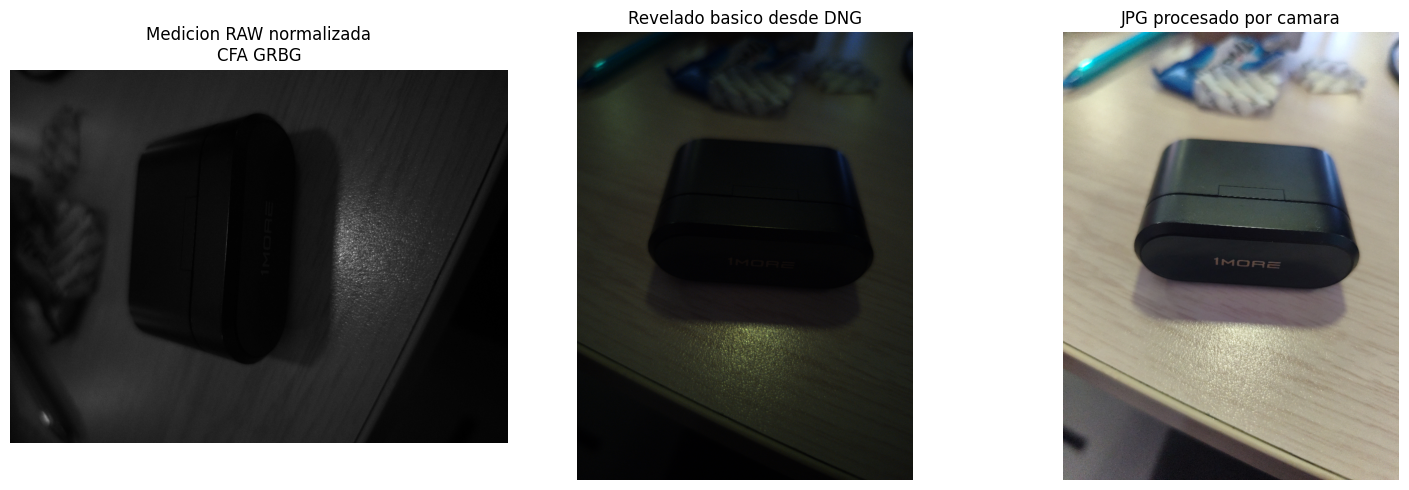

In [38]:
raw_norm = raw_mosaic_full

# Se usa una version reducida para que la visualizacion sea liviana en Colab.
max_side = 1200
scale_raw = max(raw_norm.shape) / max_side
scale_jpg = max(jpg_ref.shape[:2]) / max_side
step_raw = max(1, int(np.ceil(scale_raw)))
step_jpg = max(1, int(np.ceil(scale_jpg)))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(raw_norm[::step_raw, ::step_raw], cmap="gray")
axes[0].set_title(f"Medicion RAW normalizada\nCFA {bayer_pattern}")
axes[0].axis("off")

axes[1].imshow(rgb_from_raw[::step_raw, ::step_raw])
axes[1].set_title("Revelado basico desde DNG")
axes[1].axis("off")

axes[2].imshow(jpg_ref[::step_jpg, ::step_jpg])
axes[2].set_title("JPG procesado por camara")
axes[2].axis("off")

plt.tight_layout()
plt.show()


La captura `demo.dng` corresponde a una medicion real del sensor: contiene una sola intensidad por posicion espacial y los metadatos permiten recuperar el arreglo CFA/Bayer usado por la camara. En cambio, `demo.jpg` ya incluye el procesamiento interno del dispositivo, incluyendo demosaicking, balance de blancos, correccion de color, reduccion de ruido, nitidez, compresion y posiblemente mapeo tonal.

Por eso la comparacion visual no debe interpretarse como una metrica objetiva de demosaicking: el JPG no es una referencia lineal pura del sensor, sino una version procesada para visualizacion. Aun asi, esta seccion completa la validacion cualitativa con una captura RAW/DNG real y muestra como conectar el experimento sintetico con datos capturados por una camara.


## 3. Experimento controlado con `demo.jpg`

La evaluacion principal utiliza `demo.jpg` como imagen RGB de referencia y `demo.dng` como fuente de informacion del sensor. El archivo DNG permite recuperar el patron CFA/Bayer de la camara, sus niveles de negro y blanco y una medicion RAW real. Sin embargo, no se considera una verdad de terreno RGB, porque el DNG no contiene directamente los tres canales completos por pixel.

Por esta razon se separan dos objetivos. Primero, se construye un experimento controlado a partir de `demo.jpg`, donde la imagen RGB original es conocida antes del muestreo y permite calcular metricas objetivas. Segundo, se utiliza `demo.dng` para comprobar como los metodos se aplican a una medicion real y para observar el efecto del revelado de la camara.

En este caso,

$$
I_{\text{ref}} = I_{\text{demo.jpg}}.
$$

La imagen de referencia se redimensiona a una resolucion controlada y se normaliza al intervalo $[0,1]$. Luego se construye el mosaico sintetico $Y$ usando el patron Bayer detectado desde el DNG. El mismo mosaico y las mismas mascaras se utilizan para establecer una comparacion comun entre el metodo bilineal, SIREN y las redes convolucionales.

La secuencia experimental sera:

1. Obtener el patron Bayer y la medicion RAW desde `demo.dng`.
2. Generar un mosaico sintetico desde `demo.jpg` con ese mismo patron.
3. Reconstruir la imagen mediante interpolacion clasica y usarla como linea base.
4. Ajustar una representacion neuronal implicita SIREN a la medicion Bayer.
5. Entrenar una CNN con imagenes Kodak y evaluar su generalizacion en imagenes no vistas.
6. Comparar los metodos con las mismas metricas y visualizaciones.

La CNN se entrenara con el dataset Kodak, mientras que SIREN se analizara como una representacion ajustada a cada medicion. Finalmente, ambos enfoques se aplicaran a la captura DNG real para una comparacion cualitativa bajo una convencion comun de color.


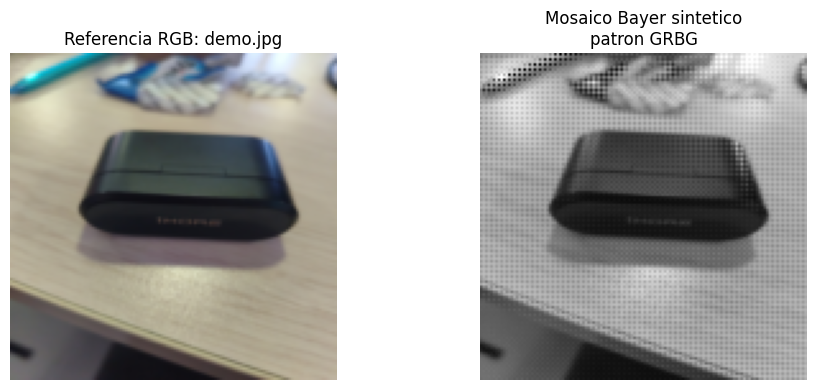

In [39]:
# Preparacion del experimento controlado con demo.jpg
def bayer_masks(height, width, pattern="RGGB"):
    patterns = {
        "RGGB": np.array([[0, 1], [1, 2]]),
        "BGGR": np.array([[2, 1], [1, 0]]),
        "GRBG": np.array([[1, 0], [2, 1]]),
        "GBRG": np.array([[1, 2], [0, 1]]),
    }
    if pattern not in patterns:
        raise ValueError(f"Patron Bayer no soportado: {pattern}")
    tile = patterns[pattern]
    masks = np.zeros((height, width, 3), dtype=np.float32)
    for row in range(2):
        for col in range(2):
            masks[row::2, col::2, tile[row, col]] = 1.0
    return masks

N = 128
rgb_reference = resize(
    jpg_ref.astype(np.float32) / 255.0,
    (N, N, 3),
    anti_aliasing=True,
    preserve_range=True,
).astype(np.float32)
rgb_reference = np.clip(rgb_reference, 0.0, 1.0)

bayer = bayer_masks(N, N, pattern=bayer_pattern)
mosaic = make_bayer_mosaic(rgb_reference, bayer) if "make_bayer_mosaic" in globals() else np.sum(rgb_reference * bayer, axis=-1).astype(np.float32)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(rgb_reference)
axes[0].set_title("Referencia RGB: demo.jpg")
axes[1].imshow(mosaic, cmap="gray", vmin=0, vmax=1)
axes[1].set_title(f"Mosaico Bayer sintetico\npatron {bayer_pattern}")
for ax in axes:
    ax.axis("off")
plt.tight_layout()


## 4. Modelo de mosaico Bayer

Para un patron Bayer de $2\times2$, se definen tres mascaras binarias:

$$
M_R, M_G, M_B \in \{0,1\}^{H \times W}.
$$

Cada mascara indica las posiciones del sensor donde se mide cada canal. En un patron RGGB, por ejemplo, hay una muestra roja, dos verdes y una azul por cada bloque local de cuatro pixeles. En el experimento controlado, la medicion mosaico se construye como

$$
Y = M_R \odot I_R + M_G \odot I_G + M_B \odot I_B,
$$

donde $\odot$ es el producto elemento a elemento e $I$ corresponde a `demo.jpg` normalizada. El patron usado no se elige arbitrariamente: se toma desde los metadatos de `demo.dng`, por eso en esta captura aparece como `GRBG`. Esta decision mantiene coherencia entre la simulacion controlada y la geometria de muestreo de la captura real.

La entrada de los modelos neuronales no sera solamente $Y$. Tambien se entregaran las mascaras, de modo que la red pueda distinguir si una intensidad observada pertenece al canal rojo, verde o azul:

$$
X = [Y, M_R, M_G, M_B] \in \mathbb{R}^{H\times W\times4}.
$$

Las mascaras no agregan informacion de color que no este en la medicion; solamente hacen explicita la geometria conocida del sensor. La consistencia entre $Y$, las mascaras y la reconstruccion sera una restriccion central tanto en el entrenamiento de la CNN como en el ajuste de SIREN.


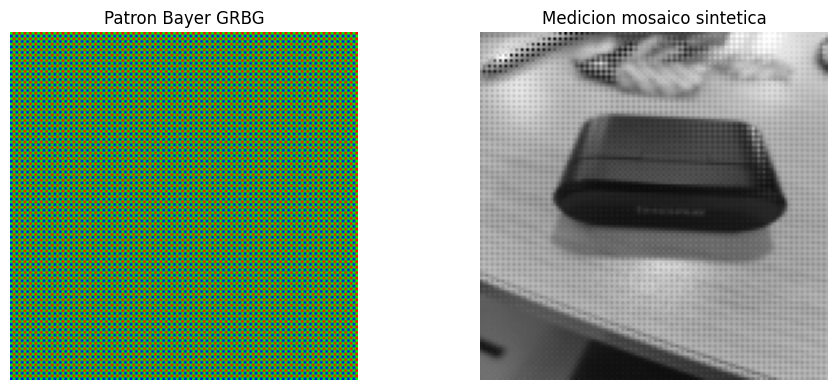

In [40]:
# Mascaras Bayer y medicion mosaico
def bayer_masks(height, width, pattern="RGGB"):
    """Construye mascaras binarias RGB para un patron Bayer de 2x2."""
    patterns = {
        "RGGB": np.array([[0, 1], [1, 2]]),
        "BGGR": np.array([[2, 1], [1, 0]]),
        "GRBG": np.array([[1, 0], [2, 1]]),
        "GBRG": np.array([[1, 2], [0, 1]]),
    }
    if pattern not in patterns:
        raise ValueError(f"Patron Bayer no soportado: {pattern}")
    tile = patterns[pattern]
    masks = np.zeros((height, width, 3), dtype=np.float32)
    for row in range(2):
        for col in range(2):
            masks[row::2, col::2, tile[row, col]] = 1.0
    return masks

def make_bayer_mosaic(rgb_image, masks):
    return np.sum(rgb_image * masks, axis=-1).astype(np.float32)

def pack_bayer_mosaic(mosaic, pattern="RGGB"):
    """Empaqueta los cuatro valores de cada bloque Bayer 2x2."""
    mosaic = np.asarray(mosaic, dtype=np.float32)
    height, width = mosaic.shape
    if height % 2 or width % 2:
        raise ValueError("El mosaico debe tener dimensiones pares")
    positions = [(0, 0), (0, 1), (1, 0), (1, 1)]
    packed = np.stack([mosaic[row::2, col::2] for row, col in positions], axis=-1)
    return packed.astype(np.float32)

def unpack_bayer_mosaic(packed):
    """Reconstruye el mosaico 2D desde sus cuatro canales empaquetados."""
    packed = np.asarray(packed, dtype=np.float32)
    height, width, channels = packed.shape
    if channels != 4:
        raise ValueError("El Bayer empaquetado debe tener cuatro canales")
    mosaic = np.zeros((2 * height, 2 * width), dtype=np.float32)
    positions = [(0, 0), (0, 1), (1, 0), (1, 1)]
    for channel, (row, col) in enumerate(positions):
        mosaic[row::2, col::2] = packed[..., channel]
    return mosaic

bayer = bayer_masks(*rgb_reference.shape[:2], pattern=bayer_pattern)
mosaic = make_bayer_mosaic(rgb_reference, bayer)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(bayer)
axes[0].set_title(f"Patron Bayer {bayer_pattern}")
axes[1].imshow(mosaic, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Medicion mosaico sintetica")
for ax in axes:
    ax.axis("off")
plt.tight_layout()


## 5. Metodo clasico de demosaicking

Como linea base, se reconstruye la imagen RGB usando un metodo tradicional de interpolacion bilineal. Para cada canal se conservan las muestras que el sensor observo y se estiman los valores faltantes mediante un promedio ponderado de las muestras vecinas del mismo canal.

La reconstruccion clasica se denotara como

$$
\hat{I}_{\text{clasico}}.
$$

Esta reconstruccion servira como referencia inicial para evaluar si los metodos neuronales entregan mejoras cuantitativas o visuales. Su ventaja es que no requiere entrenamiento y tiene un costo computacional bajo. Su limitacion es que utiliza pesos fijos y no adapta la interpolacion a los bordes, texturas o cambios cromaticos de la escena.

La linea base se aplicara en dos escenarios. En `demo.jpg` se evaluara contra la referencia RGB conocida. En Kodak se calcularan metricas sobre las imagenes de prueba. En la captura DNG real se utilizara principalmente para inspeccion visual, porque no existe una referencia RGB lineal equivalente.


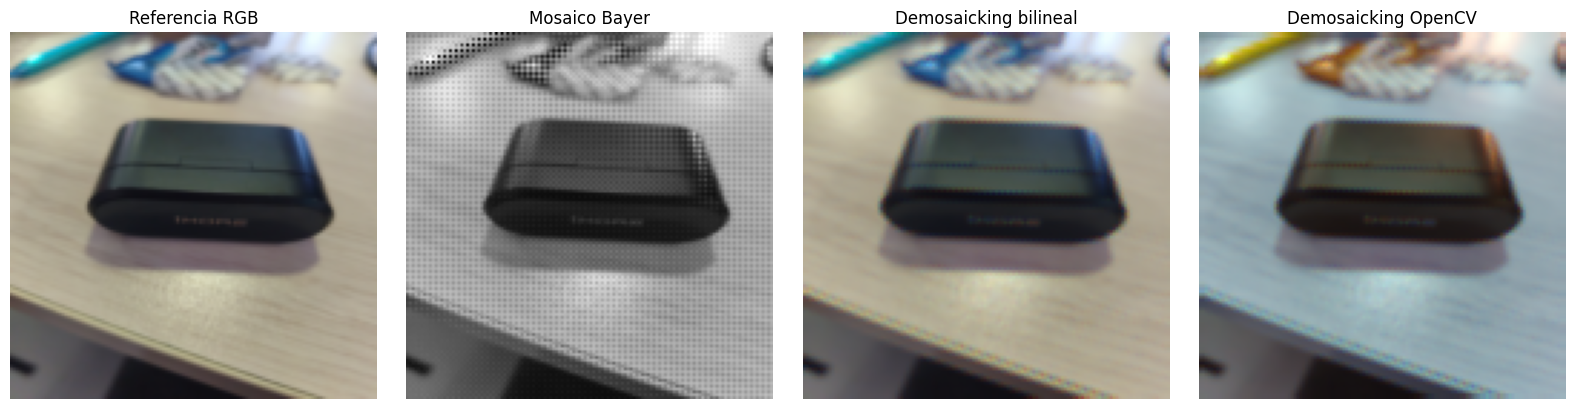

In [41]:
# Demosaicking clasico por interpolacion bilineal
def demosaic_bilinear(mosaic, masks):
    # Los kernels separables estiman los valores faltantes de cada canal.
    kernels = [
        np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]], dtype=np.float32),
        np.array([[0, 1, 0], [1, 4, 1], [0, 1, 0]], dtype=np.float32),
        np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]], dtype=np.float32),
    ]
    channels = []
    for channel, kernel in enumerate(kernels):
        observed = mosaic * masks[..., channel]
        estimate = correlate(observed, kernel, mode="mirror") / 4.0
        # Conserva exactamente las muestras que el sensor si observo.
        channels.append(np.where(masks[..., channel] > 0, observed, estimate))
    return np.clip(np.stack(channels, axis=-1), 0.0, 1.0).astype(np.float32)

I_hat_classic = demosaic_bilinear(mosaic, bayer)

def demosaic_opencv(mosaic, pattern):
    """Demosaicking bilineal de OpenCV para un patron Bayer dado."""
    # OpenCV entrega BGR con estas conversiones; se invierten los canales
    # al final para mantener el convenio RGB del resto del notebook.
    opencv_codes = {
        "RGGB": cv2.COLOR_BayerRG2BGR,
        "BGGR": cv2.COLOR_BayerBG2BGR,
        "GRBG": cv2.COLOR_BayerGR2BGR,
        "GBRG": cv2.COLOR_BayerGB2BGR,
    }
    if pattern not in opencv_codes:
        raise ValueError(f"Patron Bayer no soportado por OpenCV: {pattern}")
    mosaic_uint16 = np.rint(np.clip(mosaic, 0.0, 1.0) * 65535).astype(np.uint16)
    reconstruction = cv2.cvtColor(mosaic_uint16, opencv_codes[pattern])[..., ::-1]
    return reconstruction.astype(np.float32) / 65535.0

I_hat_opencv = demosaic_opencv(mosaic, bayer_pattern)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(rgb_reference)
axes[0].set_title("Referencia RGB")
axes[1].imshow(mosaic, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Mosaico Bayer")
axes[2].imshow(I_hat_classic)
axes[2].set_title("Demosaicking bilineal")
axes[3].imshow(I_hat_opencv)
axes[3].set_title("Demosaicking OpenCV")
for ax in axes:
    ax.axis("off")
plt.tight_layout()


## 6. Redes neuronales para demosaicking

En esta parte se comparan dos familias de modelos neuronales. Primero se implementa y evalua la CNN base solicitada en la Figura 3, luego sus variantes de arquitectura y entrenamiento. Una vez terminada la seccion CNN, se ajusta SIREN como representacion neuronal implicita sobre una medicion especifica.

La CNN aprende un modelo compartido a partir de parches de varias imagenes Kodak y se evalua sobre imagenes no vistas. SIREN, en cambio, recibe coordenadas espaciales y se optimiza para una medicion particular. Esta diferencia permite discutir generalizacion frente a ajuste especifico.

La comparacion final incluye interpolacion bilineal, OpenCV, CNN base, CNN mejoradas y SIREN. Para `demo.jpg` se dispone de una referencia RGB conocida y se reportan MSE, PSNR y SSIM. Para la captura DNG real se muestran reconstrucciones y ampliaciones cualitativas usando el revelado `rawpy` como referencia visual.

La implementacion de la CNN sigue la arquitectura de `extra/cnnDemosaicing.ipynb`; la implementacion SIREN se basa en `extra/demosaickingSiren.ipynb`.


In [42]:
# Definiciones auxiliares de SIREN; el entrenamiento se ejecuta despues de las CNN.
class SineLayer(nn.Module):
    def __init__(self, in_features, out_features, omega_0=30.0, is_first=False):
        super().__init__()
        self.omega_0 = omega_0
        self.linear = nn.Linear(in_features, out_features)
        with torch.no_grad():
            if is_first:
                self.linear.weight.uniform_(-1 / in_features, 1 / in_features)
            else:
                bound = np.sqrt(6 / in_features) / omega_0
                self.linear.weight.uniform_(-bound, bound)

    def forward(self, x):
        return torch.sin(self.omega_0 * self.linear(x))

class Siren(nn.Module):
    def __init__(self, hidden_features=256, hidden_layers=3, out_features=3):
        super().__init__()
        layers = [SineLayer(2, hidden_features, is_first=True)]
        layers += [SineLayer(hidden_features, hidden_features) for _ in range(hidden_layers)]
        layers += [nn.Linear(hidden_features, out_features)]
        self.net = nn.Sequential(*layers)

    def forward(self, coords):
        return torch.sigmoid(self.net(coords))

def build_spatial_grid(height, width):
    yy, xx = np.meshgrid(
        np.linspace(-1, 1, height, dtype=np.float32),
        np.linspace(-1, 1, width, dtype=np.float32),
        indexing="ij",
    )
    coords = np.stack([xx.ravel(), yy.ravel()], axis=1)
    return torch.from_numpy(coords).float()

def train_siren_from_mosaic(mosaic, masks, hidden_features=256, hidden_layers=3, steps=1000, learning_rate=1e-4):
    height, width = mosaic.shape
    coords = build_spatial_grid(height, width).to(DEVICE)
    mosaic_tensor = torch.from_numpy(mosaic[..., None]).float().to(DEVICE)
    masks_tensor = torch.from_numpy(masks).float().to(DEVICE)
    model = Siren(hidden_features, hidden_layers, out_features=3).to(DEVICE)
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    history = []

    model.train()
    for step in range(steps):
        rgb_prediction = model(coords).reshape(height, width, 3)
        mosaic_prediction = torch.sum(rgb_prediction * masks_tensor, dim=-1, keepdim=True)
        loss = F.mse_loss(mosaic_prediction, mosaic_tensor)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        history.append(loss.item())

    model.eval()
    with torch.no_grad():
        reconstruction = model(coords).reshape(height, width, 3).cpu().numpy()
    return model, np.clip(reconstruction, 0.0, 1.0).astype(np.float32), history



### 6.1. Red neuronal convolucional

Una red neuronal convolucional (CNN) es una funcion parametrica que aprende filtros locales compartidos espacialmente. En este problema, esos filtros aprenden a combinar la medicion Bayer con la posicion de cada muestra para estimar los tres canales RGB faltantes. La red se entrena de forma supervisada: recibe un mosaico sintetico y se compara su salida con la imagen RGB original.

La implementacion sigue la arquitectura base de la Figura 3 y la referencia `extra/cnnDemosaicing.ipynb`: un encoder-decoder con `MaxPooling`, convoluciones transpuestas y conexiones `add`. La entrada es un Bayer empaquetado de 4 canales y la salida RGB tiene el doble de resolucion espacial. En la verificacion de arquitectura se usa entrada 128 x 128 y salida 256 x 256, tal como en la figura; durante el entrenamiento se usan parches 64 x 64 -> 128 x 128 para controlar el costo. Con la configuracion base, el resumen debe reportar 14,967 parametros entrenables. Se implementa en PyTorch porque el notebook principal ya utiliza este framework.

La entrada se define como

$$
X_{\text{CNN}} = [Y_{00},Y_{01},Y_{10},Y_{11}] \in \mathbb{R}^{H/2 \times W/2 \times 4}.
$$

La CNN aprende una funcion

$$
g_\phi: \mathbb{R}^{H/2 \times W/2 \times 4} \rightarrow \mathbb{R}^{H \times W \times 3}.
$$

La primera capa recibe los cuatro valores Bayer de cada bloque 2 x 2 empaquetados en canales. La ultima capa entrega tres canales RGB y utiliza una sigmoide para mantener los valores en $[0,1]$. La perdida principal es el error cuadratico medio entre la salida y la referencia RGB. Se agrega una perdida de consistencia del sensor, que vuelve a muestrear la salida RGB en las cuatro posiciones Bayer y penaliza que contradiga las mediciones disponibles.

La CNN se entrena con parches de varias imagenes del dataset Kodak y se evalua sobre imagenes completas no utilizadas durante el entrenamiento. Asi, sus resultados miden capacidad de generalizacion y no solo ajuste a una captura individual.


In [43]:
# Red neuronal convolucional inspirada en la Figura 3 del enunciado.
class ResidualBlock(nn.Module):
    def __init__(self, channels, kernel_size=3):
        super().__init__()
        padding = kernel_size // 2
        self.block = nn.Sequential(
            nn.Conv2d(channels, channels, kernel_size, padding=padding),
            nn.ReLU(inplace=True),
            nn.Conv2d(channels, channels, kernel_size, padding=padding),
        )

    def forward(self, x):
        return x + self.block(x)

class DemosaicCNN(nn.Module):
    """Arquitectura base de la Figura 3 del enunciado.

    La entrada es un Bayer empaquetado de 4 canales y la salida tiene
    el doble de resolucion espacial. Para una entrada 64x64, la red
    entrega una reconstruccion RGB 128x128, como en la tarea.
    """
    def __init__(self, input_channels=4, hidden_channels=16, num_blocks=0):
        super().__init__()
        channels = hidden_channels

        # Encoder de la Figura 3: 64 -> 32 -> 16 -> 8 -> 4.
        self.encoder_first = nn.Conv2d(input_channels, channels, 2, stride=2)
        self.pool1 = nn.MaxPool2d(2)
        self.encoder_32 = nn.Conv2d(channels, channels, 3, padding=1)
        self.encoder_16 = nn.Conv2d(channels, channels, 3, stride=2, padding=1)
        self.pool2 = nn.MaxPool2d(2)
        self.bottleneck = nn.Sequential(
            nn.Conv2d(channels, channels, 3, padding=1),
            *[ResidualBlock(channels) for _ in range(num_blocks)],
        )

        # Decoder de la Figura 3: 4 -> 8 -> 16 -> 32 -> 64 -> 128.
        self.decoder_8 = nn.ConvTranspose2d(channels, channels, 3, stride=2, padding=1, output_padding=1)
        self.decoder_16 = nn.ConvTranspose2d(channels, channels, 3, stride=2, padding=1, output_padding=1)
        self.decoder_32 = nn.ConvTranspose2d(channels, channels, 3, stride=2, padding=1, output_padding=1)
        self.decoder_64 = nn.ConvTranspose2d(channels, input_channels, 3, stride=2, padding=1, output_padding=1)
        self.decoder_128 = nn.ConvTranspose2d(input_channels, 3, 3, stride=2, padding=1, output_padding=1)
        self.output_layer = nn.Conv2d(3, 3, 3, padding=1)

    def activate(self, x):
        return F.gelu(x)

    def forward(self, x):
        x1 = self.activate(self.encoder_first(x))
        x2 = self.activate(self.encoder_32(self.pool1(x1)))
        x3 = self.activate(self.encoder_16(x2))
        features = self.activate(self.bottleneck(self.pool2(x3)))

        features = self.activate(self.decoder_8(features))
        features = self.activate(self.decoder_16(features)) + x2
        features = self.activate(self.decoder_32(features)) + x1
        features = self.activate(self.decoder_64(features)) + x
        features = self.activate(self.decoder_128(features))
        return torch.sigmoid(self.output_layer(features))

def sensor_consistency_loss(prediction, input_tensor, pattern=None):
    """Compara la prediccion RGB con las cuatro muestras CFA empaquetadas."""
    pattern = pattern or globals().get("bayer_pattern", "GRBG")
    positions = [(0, 0), (0, 1), (1, 0), (1, 1)]
    channel_indices = {"R": 0, "G": 1, "B": 2}
    observed = []
    for (row, col), letter in zip(positions, pattern):
        observed.append(prediction[:, channel_indices[letter], row::2, col::2])
    reprojected = torch.stack(observed, dim=1)
    return F.mse_loss(reprojected, input_tensor)

# Configuracion base y verificacion efectiva de la arquitectura.
# El valor por defecto mantiene esta celda segura si se ejecuta de forma aislada.
CNN_BASE_CONFIG = globals().get("CNN_BASE_CONFIG", {
    "input_channels": 4,
    "hidden_channels": 16,
    "num_blocks": 0,
    "epochs": 6,
    "learning_rate": 1e-3,
    "batch_size": 32,
    "physics_weight": 0.1,
})

def count_trainable_parameters(model):
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)

def parameter_summary(model):
    """Resume parametros totales, entrenables y no entrenables."""
    total = sum(parameter.numel() for parameter in model.parameters())
    trainable = count_trainable_parameters(model)
    return pd.DataFrame([{
        "Parametros totales": total,
        "Parametros entrenables": trainable,
        "Parametros no entrenables": total - trainable,
    }])

def layer_summary(model, sample):
    """Construye una tabla tipo model.summary para las capas con parametros."""
    rows = []
    hooks = []

    def capture(module_name):
        def hook(module, inputs, output):
            output_shape = tuple(output.shape) if hasattr(output, "shape") else str(type(output))
            rows.append({
                "Capa": module_name,
                "Tipo": module.__class__.__name__,
                "Forma de salida": output_shape,
                "Parametros": sum(parameter.numel() for parameter in module.parameters()),
            })
        return hook

    for name, module in model.named_modules():
        if name and not list(module.children()):
            hooks.append(module.register_forward_hook(capture(name)))
    model.eval()
    with torch.no_grad():
        model(sample)
    for hook in hooks:
        hook.remove()
    return pd.DataFrame(rows)

model_cnn_base = DemosaicCNN(
    input_channels=CNN_BASE_CONFIG["input_channels"],
    hidden_channels=CNN_BASE_CONFIG["hidden_channels"],
    num_blocks=CNN_BASE_CONFIG["num_blocks"],
).to(DEVICE)
dummy_input = torch.zeros(1, 4, 128, 128, device=DEVICE)
with torch.no_grad():
    dummy_output = model_cnn_base(dummy_input)

print(model_cnn_base)
print(f"Forma de entrada: {tuple(dummy_input.shape)}")
print(f"Forma de salida:  {tuple(dummy_output.shape)}")
print(f"Parametros entrenables: {count_trainable_parameters(model_cnn_base):,}")
display(layer_summary(model_cnn_base, dummy_input))
display(parameter_summary(model_cnn_base))
display(pd.DataFrame([CNN_BASE_CONFIG]))


DemosaicCNN(
  (encoder_first): Conv2d(4, 16, kernel_size=(2, 2), stride=(2, 2))
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (encoder_32): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (encoder_16): Conv2d(16, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (bottleneck): Sequential(
    (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  )
  (decoder_8): ConvTranspose2d(16, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
  (decoder_16): ConvTranspose2d(16, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
  (decoder_32): ConvTranspose2d(16, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
  (decoder_64): ConvTranspose2d(16, 4, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
  (decoder_128): ConvT

,Capa,Tipo,Forma de salida,Parametros
0,encoder_first,Conv2d,"(1, 16, 64, 64)",272
1,pool1,MaxPool2d,"(1, 16, 32, 32)",0
2,encoder_32,Conv2d,"(1, 16, 32, 32)",2320
3,encoder_16,Conv2d,"(1, 16, 16, 16)",2320
4,pool2,MaxPool2d,"(1, 16, 8, 8)",0
5,bottleneck.0,Conv2d,"(1, 16, 8, 8)",2320
6,decoder_8,ConvTranspose2d,"(1, 16, 16, 16)",2320
7,decoder_16,ConvTranspose2d,"(1, 16, 32, 32)",2320
8,decoder_32,ConvTranspose2d,"(1, 16, 64, 64)",2320
9,decoder_64,ConvTranspose2d,"(1, 4, 128, 128)",580


,Parametros totales,Parametros entrenables,Parametros no entrenables
0,14967,14967,0


,input_channels,hidden_channels,num_blocks,epochs,learning_rate,batch_size,physics_weight
0,4,16,0,6,0.001,32,0.1


#### 6.1.1. Entrenamiento de la CNN con varias imagenes

La CNN se entrena exclusivamente con el dataset Kodak, siguiendo la organizacion de `extra/cnnDemosaicing.ipynb`. Las imagenes RGB son la verdad de terreno; para cada parche se genera artificialmente el mosaico Bayer y se empaquetan sus cuatro muestras por bloque 2 x 2. Por lo tanto, cada ejemplo supervisado tiene la forma

$$
X = [Y_{00}, Y_{01}, Y_{10}, Y_{11}], \qquad I_{\mathrm{target}} = I_{\mathrm{RGB}},
$$

La division es por imagen completa, no por parche aleatorio: se utilizan las primeras 20 imagenes Kodak para entrenamiento y las ultimas 4 para prueba. Esto evita que parches de una misma fotografia aparezcan en ambos conjuntos. Con parches RGB de 128 x 128, entrada Bayer empaquetada de 64 x 64 y `stride=128`, el notebook informa explicitamente el numero de parches generado en cada particion.

La configuracion base de la Figura 3 es: 4 canales Bayer empaquetados, 16 canales internos, sin bloques residuales adicionales, 6 epocas, tasa de aprendizaje $10^{-3}$, batch de 32 ejemplos y peso $0.1$ para la consistencia del sensor. El optimizador es Adam y la perdida total es

$$
\mathcal{L} = \mathcal{L}_{\mathrm{RGB}} + 0.1\,\mathcal{L}_{\mathrm{sensor}},\qquad
\mathcal{L}_{\mathrm{RGB}} = \|\hat I-I_{\mathrm{RGB}}\|_2^2.
$$

La celda siguiente entrena el modelo base y muestra por epoca la perdida total, la perdida RGB supervisada y la perdida de consistencia fisica. Tambien imprime y tabula los parametros totales y entrenables del modelo. Luego se evalua el error en los parches de las cuatro imagenes Kodak reservadas para prueba.


Imagenes de entrenamiento: 20
Imagenes de prueba: 4
Parches de entrenamiento: 480
Parches de prueba: 96
Parametros entrenables: 14,967
Epoca 01/6 | total: 0.069708 | RGB: 0.063428 | fisica: 0.062801
Epoca 02/6 | total: 0.066830 | RGB: 0.060812 | fisica: 0.060182
Epoca 03/6 | total: 0.063807 | RGB: 0.058028 | fisica: 0.057791
Epoca 04/6 | total: 0.059592 | RGB: 0.054114 | fisica: 0.054786
Epoca 05/6 | total: 0.051416 | RGB: 0.046659 | fisica: 0.047563
Epoca 06/6 | total: 0.037216 | RGB: 0.033712 | fisica: 0.035046
MSE promedio en parches de prueba Kodak: 0.020789
Parametros de la CNN base: 14,967


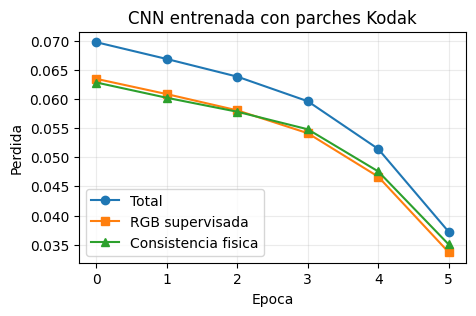

In [44]:
# Dataset Kodak para entrenamiento supervisado multi-imagen
# Salvaguarda para ejecucion parcial de esta seccion.
CNN_BASE_CONFIG = globals().get("CNN_BASE_CONFIG", {
    "input_channels": 4, "hidden_channels": 16, "num_blocks": 0,
    "epochs": 6, "learning_rate": 1e-3, "batch_size": 32, "physics_weight": 0.1,
})
# Rutas para ejecucion local o Colab
try:
    from google.colab import files  # noqa: F401
    IN_COLAB = True
except Exception:
    IN_COLAB = False

REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "tareas" / "tarea-02").exists() and Path.cwd().name == "tarea-02":
    REPO_ROOT = Path.cwd().parents[1]

TASK_DIR = REPO_ROOT / "tareas" / "tarea-02"
LOCAL_DATASET_DIR = REPO_ROOT / "tareas" / "dataset"
DATA_DIR = Path("/content") if IN_COLAB else TASK_DIR

KODAK_DIR = DATA_DIR / "kodak"
KODAK_DIR.mkdir(exist_ok=True)
KODAK_ZIP = KODAK_DIR / "kodak.zip"
KODAK_URL = "https://arizona.box.com/shared/static/5bk6qar4vgfizmhum8onreu6sp90bz2i"

# El repositorio tambien trae tareas/dataset/01.png ... 24.png; se usa como respaldo local.
def select_local_kodak_paths(dataset_dir):
    if not dataset_dir.exists():
        return []
    selected = []
    for index in range(1, 25):
        candidates = [dataset_dir / f"{index:02d}.png", dataset_dir / f"{index}.png"]
        selected.extend([path for path in candidates if path.exists()][:1])
    return selected

local_kodak_paths = select_local_kodak_paths(LOCAL_DATASET_DIR)
if len(local_kodak_paths) >= 8:
    kodak_paths = local_kodak_paths
else:
    if not list(KODAK_DIR.rglob("kodim*.png")):
        urllib.request.urlretrieve(KODAK_URL, KODAK_ZIP)
        with zipfile.ZipFile(KODAK_ZIP, "r") as zip_ref:
            zip_ref.extractall(KODAK_DIR)
    kodak_paths = sorted(KODAK_DIR.rglob("kodim*.png"))

if len(kodak_paths) < 8:
    raise RuntimeError(f"Se encontraron {len(kodak_paths)} imagenes Kodak; revisa la descarga o tareas/dataset.")

kodak_paths = kodak_paths[:24]
train_paths = kodak_paths[:-4]
test_paths = kodak_paths[-4:]
print(f"Imagenes de entrenamiento: {len(train_paths)}")
print(f"Imagenes de prueba: {len(test_paths)}")

class KodakPatchDataset(Dataset):
    def __init__(self, image_paths, patch_size=128, stride=128, max_patches_per_image=None):
        self.samples = []
        self.patch_size = patch_size
        for path in image_paths:
            image = np.asarray(Image.open(path).convert("RGB"), dtype=np.float32) / 255.0
            height, width = image.shape[:2]
            image_samples = []
            for top in range(0, height - patch_size + 1, stride):
                for left in range(0, width - patch_size + 1, stride):
                    image_samples.append(image[top:top + patch_size, left:left + patch_size])
            if max_patches_per_image is not None:
                image_samples = image_samples[:max_patches_per_image]
            self.samples.extend(image_samples)

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        rgb = self.samples[index]
        masks = bayer_masks(self.patch_size, self.patch_size, pattern=bayer_pattern)
        mosaic_patch = make_bayer_mosaic(rgb, masks)
        # La Figura 3 recibe cuatro muestras Bayer empaquetadas y reconstruye
        # el parche RGB de resolucion doble.
        input_patch = pack_bayer_mosaic(mosaic_patch, pattern=bayer_pattern)
        input_tensor = torch.from_numpy(input_patch.transpose(2, 0, 1)).float()
        target_tensor = torch.from_numpy(rgb.transpose(2, 0, 1)).float()
        return input_tensor, target_tensor

train_dataset = KodakPatchDataset(train_paths, patch_size=128, stride=128)
test_dataset = KodakPatchDataset(test_paths, patch_size=128, stride=128)
train_loader = DataLoader(train_dataset, batch_size=CNN_BASE_CONFIG["batch_size"], shuffle=True, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=CNN_BASE_CONFIG["batch_size"], shuffle=False, num_workers=0)
print(f"Parches de entrenamiento: {len(train_dataset)}")
print(f"Parches de prueba: {len(test_dataset)}")

def train_cnn_loader(model, loader, epochs=6, learning_rate=1e-3, physics_weight=0.1):
    """Entrena la CNN y conserva cada componente de la perdida."""
    model.train()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    history = {"total": [], "rgb": [], "fisica": []}
    print(f"Parametros entrenables: {count_trainable_parameters(model):,}")
    for epoch in range(epochs):
        totals = {"total": 0.0, "rgb": 0.0, "fisica": 0.0}
        seen = 0
        for inputs, targets in loader:
            inputs = inputs.to(DEVICE)
            targets = targets.to(DEVICE)
            predictions = model(inputs)
            rgb_loss = F.mse_loss(predictions, targets)
            physics_loss = sensor_consistency_loss(predictions, inputs)
            loss = rgb_loss + physics_weight * physics_loss
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            batch_size = inputs.size(0)
            seen += batch_size
            totals["total"] += loss.item() * batch_size
            totals["rgb"] += rgb_loss.item() * batch_size
            totals["fisica"] += physics_loss.item() * batch_size
        epoch_values = {name: value / max(seen, 1) for name, value in totals.items()}
        for name in history:
            history[name].append(epoch_values[name])
        print(
            f"Epoca {epoch + 1:02d}/{epochs} | "
            f"total: {epoch_values['total']:.6f} | "
            f"RGB: {epoch_values['rgb']:.6f} | "
            f"fisica: {epoch_values['fisica']:.6f}"
        )
    return history

def evaluate_cnn_loader(model, loader):
    model.eval()
    loss_sum, sample_count = 0.0, 0
    with torch.no_grad():
        for inputs, targets in loader:
            predictions = model(inputs.to(DEVICE)).cpu()
            batch_size = inputs.size(0)
            loss_sum += F.mse_loss(predictions, targets).item() * batch_size
            sample_count += batch_size
    return loss_sum / max(sample_count, 1)

def trim_to_even(image):
    height = image.shape[0] - image.shape[0] % 2
    width = image.shape[1] - image.shape[1] % 2
    return image[:height, :width]

def predict_cnn_on_mosaic(model, mosaic_image, pattern, tile_size=64, overlap=16):
    """Reconstruye un mosaico completo usando Bayer empaquetado y solapamiento."""
    if not 0 <= overlap < tile_size:
        raise ValueError("overlap debe estar entre 0 y tile_size - 1")
    mosaic_image = trim_to_even(np.asarray(mosaic_image, dtype=np.float32))
    height, width = mosaic_image.shape
    packed = pack_bayer_mosaic(mosaic_image, pattern=pattern)
    packed_height, packed_width = packed.shape[:2]
    padded_height = max(packed_height, tile_size)
    padded_width = max(packed_width, tile_size)
    packed_padded = np.pad(
        packed, ((0, padded_height - packed_height), (0, padded_width - packed_width), (0, 0)), mode="edge"
    )
    output_height, output_width = padded_height * 2, padded_width * 2
    reconstruction = np.zeros((output_height, output_width, 3), dtype=np.float32)
    weights = np.zeros((output_height, output_width, 1), dtype=np.float32)
    stride = tile_size - overlap

    def tile_starts(length):
        starts = list(range(0, max(length - tile_size, 0) + 1, stride))
        last_start = max(length - tile_size, 0)
        if not starts or starts[-1] != last_start:
            starts.append(last_start)
        return starts

    model.eval()
    with torch.no_grad():
        for top in tile_starts(padded_height):
            for left in tile_starts(padded_width):
                input_tile = packed_padded[top:top + tile_size, left:left + tile_size]
                input_tensor = torch.from_numpy(input_tile.transpose(2, 0, 1)[None]).float().to(DEVICE)
                prediction = model(input_tensor)[0].cpu().numpy().transpose(1, 2, 0)
                out_top, out_left = 2 * top, 2 * left
                out_bottom, out_right = out_top + prediction.shape[0], out_left + prediction.shape[1]
                reconstruction[out_top:out_bottom, out_left:out_right] += prediction
                weights[out_top:out_bottom, out_left:out_right] += 1.0
    reconstruction = reconstruction / np.maximum(weights, 1.0)
    return np.clip(reconstruction[:height, :width], 0.0, 1.0)

model_cnn_kodak = DemosaicCNN(
    input_channels=CNN_BASE_CONFIG["input_channels"],
    hidden_channels=CNN_BASE_CONFIG["hidden_channels"],
    num_blocks=CNN_BASE_CONFIG["num_blocks"],
).to(DEVICE)
kodak_loss_history = train_cnn_loader(
    model_cnn_kodak,
    train_loader,
    epochs=CNN_BASE_CONFIG["epochs"],
    learning_rate=CNN_BASE_CONFIG["learning_rate"],
    physics_weight=CNN_BASE_CONFIG["physics_weight"],
)
kodak_test_mse = evaluate_cnn_loader(model_cnn_kodak, test_loader)
print(f"MSE promedio en parches de prueba Kodak: {kodak_test_mse:.6f}")
print(f"Parametros de la CNN base: {count_trainable_parameters(model_cnn_kodak):,}")

plt.figure(figsize=(5, 3))
plt.plot(kodak_loss_history["total"], marker="o", label="Total")
plt.plot(kodak_loss_history["rgb"], marker="s", label="RGB supervisada")
plt.plot(kodak_loss_history["fisica"], marker="^", label="Consistencia fisica")
plt.xlabel("Epoca")
plt.ylabel("Perdida")
plt.title("CNN entrenada con parches Kodak")
plt.legend()
plt.grid(alpha=0.25)
plt.show()


#### 6.1.2. Variantes experimentales

Para estudiar cambios concretos se mantiene fija la semilla conceptual del experimento: mismo conjunto Kodak, mismo patron Bayer, mismo tamano de parche, mismo optimizador, misma perdida y seis epocas. Se modifica un solo factor por vez respecto de la configuracion base.

| Experimento | Cambio respecto a la base | Learning rate | Batch | Bloques residuales | Canales | Peso fisico |
|---|---|---:|---:|---:|---:|---:|
| CNN base Figura 3 | Ninguno | $10^{-3}$ | 32 | 0 | 16 | 0.1 |
| CNN mejorada | 32 canales y 6 bloques residuales | $10^{-3}$ | 32 | 6 | 32 | 0.1 |
| CNN mejorada sin fisica | Se elimina la perdida fisica | $10^{-3}$ | 32 | 6 | 32 | 0.0 |

Cada bloque residual contiene dos convoluciones 2D. La CNN base no agrega bloques residuales: conserva exactamente la arquitectura de la Figura 3. Las variantes aumentan la capacidad con 32 canales y 6 bloques. La comparacion se reporta tanto sobre las imagenes Kodak de prueba como sobre `demo.jpg`, la imagen controlada de este trabajo. En ambas evaluaciones, un MSE menor y un PSNR/SSIM mayor indican una reconstruccion mejor.


In [45]:
# Variantes de arquitectura y entrenamiento para la CNN Kodak
CNN_BASE_CONFIG = globals().get("CNN_BASE_CONFIG", {
    "input_channels": 4, "hidden_channels": 16, "num_blocks": 0,
    "epochs": 6, "learning_rate": 1e-3, "batch_size": 32, "physics_weight": 0.1,
})
cnn_experiments = [
    {**CNN_BASE_CONFIG, "nombre": "CNN base Figura 3"},
    {**CNN_BASE_CONFIG, "nombre": "CNN mejorada", "hidden_channels": 32, "num_blocks": 6},
    {**CNN_BASE_CONFIG, "nombre": "CNN mejorada sin fisica", "hidden_channels": 32, "num_blocks": 6, "physics_weight": 0.0},
]

def evaluate_cnn_on_controlled_image(model):
    """Evalua una CNN sobre demo.jpg, cuya referencia RGB es conocida."""
    prediction = predict_cnn_on_mosaic(model, mosaic, bayer_pattern, tile_size=64, overlap=16)
    mse = float(np.mean((rgb_reference - prediction) ** 2))
    psnr_value = float(10.0 * np.log10(1.0 / max(mse, 1e-12)))
    ssim_value = float(ssim(rgb_reference, prediction, channel_axis=-1, data_range=1.0))
    return mse, psnr_value, ssim_value

def run_cnn_experiment(config):
    start_time = time.perf_counter()
    experiment_loader = DataLoader(
        train_dataset, batch_size=config["batch_size"], shuffle=True, num_workers=0
    )
    model = DemosaicCNN(
        input_channels=config["input_channels"],
        hidden_channels=config["hidden_channels"],
        num_blocks=config["num_blocks"],
    ).to(DEVICE)
    history = train_cnn_loader(
        model,
        experiment_loader,
        epochs=config["epochs"],
        learning_rate=config["learning_rate"],
        physics_weight=config["physics_weight"],
    )
    test_mse = evaluate_cnn_loader(model, test_loader)
    controlled_mse, controlled_psnr, controlled_ssim = evaluate_cnn_on_controlled_image(model)
    row = {
        "metodo": config["nombre"],
        "learning rate": config["learning_rate"],
        "batch": config["batch_size"],
        "canales": config["hidden_channels"],
        "bloques residuales": config["num_blocks"],
        "epocas": config["epochs"],
        "MSE Kodak prueba": test_mse,
        "MSE demo.jpg": controlled_mse,
        "PSNR demo.jpg [dB]": controlled_psnr,
        "SSIM demo.jpg": controlled_ssim,
        "parametros": count_trainable_parameters(model),
        "tiempo [s]": time.perf_counter() - start_time,
    }
    return row, history, model

variant_rows = []
variant_histories = {}
variant_models = {}
for config in cnn_experiments:
    row, history, model = run_cnn_experiment(config)
    variant_rows.append(row)
    variant_histories[config["nombre"]] = history
    variant_models[config["nombre"]] = model

variants_df = pd.DataFrame(variant_rows).sort_values("MSE Kodak prueba")
display(variants_df.round(4))


Parametros entrenables: 14,967
Epoca 01/6 | total: 0.062720 | RGB: 0.056881 | fisica: 0.058396
Epoca 02/6 | total: 0.060128 | RGB: 0.054572 | fisica: 0.055568
Epoca 03/6 | total: 0.055600 | RGB: 0.050479 | fisica: 0.051213
Epoca 04/6 | total: 0.047048 | RGB: 0.042668 | fisica: 0.043797
Epoca 05/6 | total: 0.037474 | RGB: 0.033968 | fisica: 0.035061
Epoca 06/6 | total: 0.030914 | RGB: 0.028039 | fisica: 0.028747
Parametros entrenables: 168,359
Epoca 01/6 | total: 0.062619 | RGB: 0.056879 | fisica: 0.057402
Epoca 02/6 | total: 0.059087 | RGB: 0.053681 | fisica: 0.054065
Epoca 03/6 | total: 0.048995 | RGB: 0.044573 | fisica: 0.044215
Epoca 04/6 | total: 0.041938 | RGB: 0.038211 | fisica: 0.037270
Epoca 05/6 | total: 0.038165 | RGB: 0.034793 | fisica: 0.033718
Epoca 06/6 | total: 0.034805 | RGB: 0.031746 | fisica: 0.030586
Parametros entrenables: 168,359
Epoca 01/6 | total: 0.056512 | RGB: 0.056512 | fisica: 0.057619
Epoca 02/6 | total: 0.053104 | RGB: 0.053104 | fisica: 0.055081
Epoca 03/

,metodo,learning rate,batch,canales,bloques residuales,epocas,MSE Kodak prueba,MSE demo.jpg,PSNR demo.jpg [dB],SSIM demo.jpg,parametros,tiempo [s]
2,CNN mejorada sin fisica,0.001,32,32,6,6,0.0142,0.0138,18.6135,0.4455,168359,2.7890
0,CNN base Figura 3,0.001,32,16,0,6,0.0209,0.0195,17.0993,0.4610,14967,2.7715
1,CNN mejorada,0.001,32,32,6,6,0.0245,0.0229,16.4087,0.4426,168359,3.1892


### 6.2. Representacion neuronal implicita SIREN

Una vez entrenadas y comparadas las CNN, se ajusta SIREN sobre el mosaico controlado. Esta representacion recibe coordenadas espaciales y reconstruye RGB para una medicion especifica.

## 7. Aplicacion de las redes a la captura DNG real

La CNN se entrena con varias imagenes RGB de Kodak y luego se aplica, sin volver a entrenarla, a la medicion mosaico real del DNG. La inferencia se realiza por bloques con solapamiento y promedio para reducir costuras. La INR-SIREN se optimiza sobre un recorte central de la medicion real, porque esta representacion se ajusta a una captura especifica.

Antes de la visualizacion final, las reconstrucciones RGB del DNG pasan por una etapa comun de revelado: matriz de correccion de color y gamma sRGB. Esto permite comparar los metodos en una misma convencion de color.

Como el DNG no contiene una verdad RGB lineal perfecta, la comparacion con `rawpy` y con el JPG de la camara se interpreta cualitativamente. Las metricas objetivas se reportan para Kodak, donde si conocemos la referencia RGB.


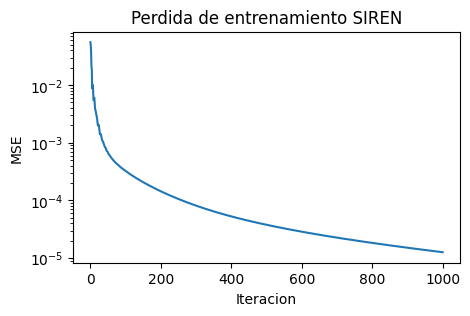

Guardada: /content/dng_bilinear_color_corrected.png
Guardada: /content/dng_opencv_color_corrected.png
Guardada: /content/dng_cnn_color_corrected.png
Guardada: /content/dng_inr_color_corrected.png
Guardada: /content/dng_cnn_cnn_base_figura_3_color_corrected.png
Guardada: /content/dng_cnn_cnn_mejorada_color_corrected.png
Guardada: /content/dng_cnn_cnn_mejorada_sin_fisica_color_corrected.png


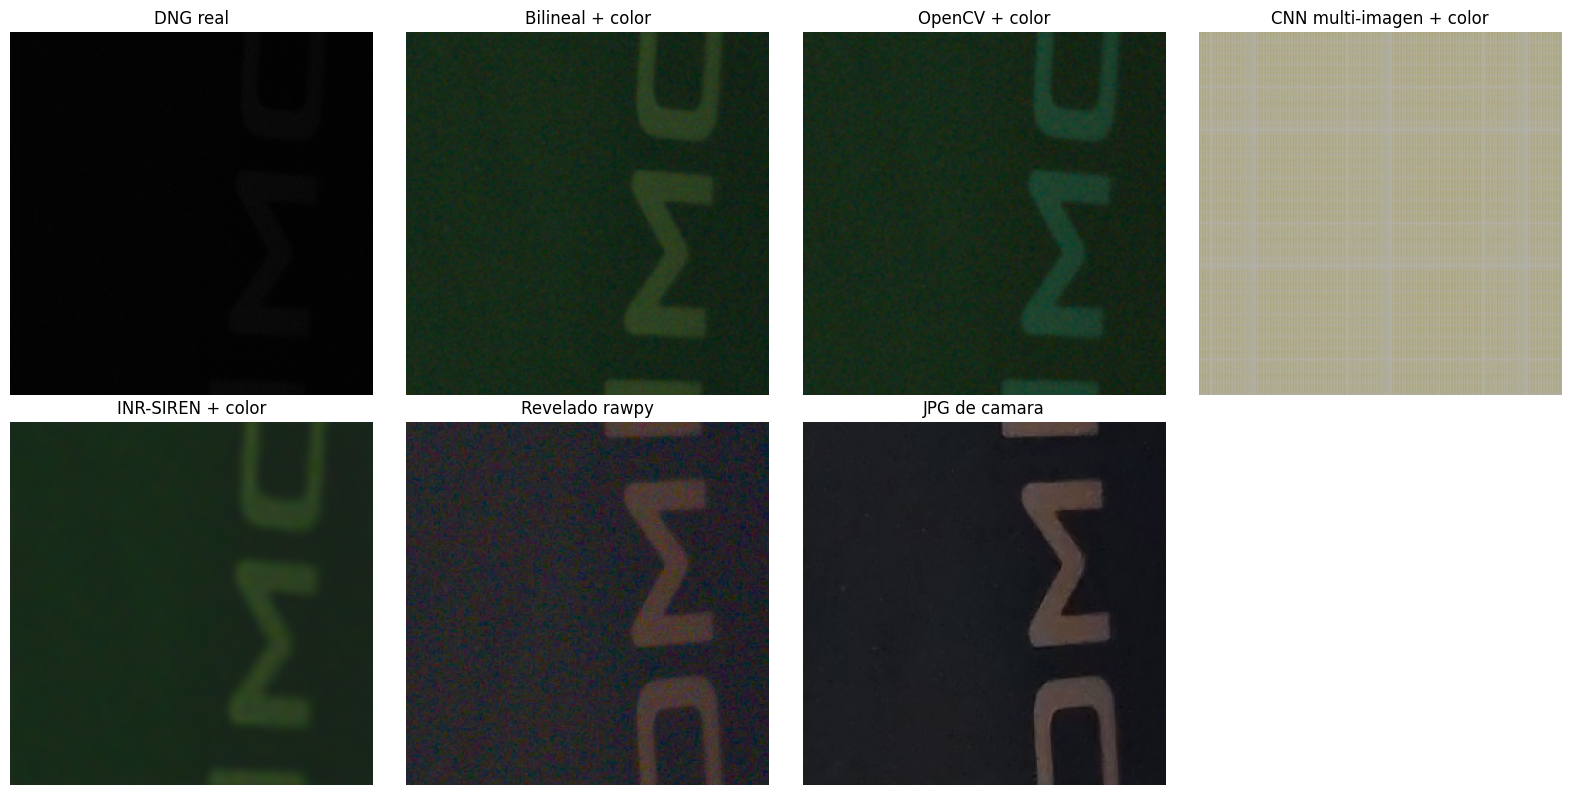

In [46]:
# La SIREN se entrena despues de completar la seccion CNN.
model_inr, I_hat_inr, loss_history = train_siren_from_mosaic(
    mosaic, bayer, hidden_features=256, hidden_layers=3, steps=1000
)
plt.figure(figsize=(5, 3))
plt.plot(loss_history)
plt.yscale("log")
plt.title("Perdida de entrenamiento SIREN")
plt.xlabel("Iteracion")
plt.ylabel("MSE")
plt.show()

def trim_to_even(image):
    height = image.shape[0] - image.shape[0] % 2
    width = image.shape[1] - image.shape[1] % 2
    return image[:height, :width]

def predict_cnn_on_mosaic(model, mosaic_image, pattern, tile_size=64, overlap=16):
    """Reconstruye un mosaico completo usando Bayer empaquetado y solapamiento."""
    if not 0 <= overlap < tile_size:
        raise ValueError("overlap debe estar entre 0 y tile_size - 1")
    mosaic_image = trim_to_even(np.asarray(mosaic_image, dtype=np.float32))
    height, width = mosaic_image.shape
    packed = pack_bayer_mosaic(mosaic_image, pattern=pattern)
    packed_height, packed_width = packed.shape[:2]
    padded_height = max(packed_height, tile_size)
    padded_width = max(packed_width, tile_size)
    packed_padded = np.pad(
        packed, ((0, padded_height - packed_height), (0, padded_width - packed_width), (0, 0)), mode="edge"
    )
    output_height, output_width = padded_height * 2, padded_width * 2
    reconstruction = np.zeros((output_height, output_width, 3), dtype=np.float32)
    weights = np.zeros((output_height, output_width, 1), dtype=np.float32)
    stride = tile_size - overlap

    def tile_starts(length):
        starts = list(range(0, max(length - tile_size, 0) + 1, stride))
        last_start = max(length - tile_size, 0)
        if not starts or starts[-1] != last_start:
            starts.append(last_start)
        return starts

    model.eval()
    with torch.no_grad():
        for top in tile_starts(padded_height):
            for left in tile_starts(padded_width):
                input_tile = packed_padded[top:top + tile_size, left:left + tile_size]
                input_tensor = torch.from_numpy(input_tile.transpose(2, 0, 1)[None]).float().to(DEVICE)
                prediction = model(input_tensor)[0].cpu().numpy().transpose(1, 2, 0)
                out_top, out_left = 2 * top, 2 * left
                out_bottom, out_right = out_top + prediction.shape[0], out_left + prediction.shape[1]
                reconstruction[out_top:out_bottom, out_left:out_right] += prediction
                weights[out_top:out_bottom, out_left:out_right] += 1.0
    reconstruction = reconstruction / np.maximum(weights, 1.0)
    return np.clip(reconstruction[:height, :width], 0.0, 1.0)

real_mosaic = trim_to_even(raw_mosaic_full)
real_bayer = bayer_masks(*real_mosaic.shape, pattern=bayer_pattern)
I_hat_dng_bilinear = demosaic_bilinear(real_mosaic, real_bayer)
I_hat_dng_opencv = demosaic_opencv(real_mosaic, bayer_pattern)
I_hat_dng_cnn = predict_cnn_on_mosaic(model_cnn_kodak, real_mosaic, bayer_pattern)
I_hat_dng_cnn_variants = {}
if "variant_models" in globals():
    I_hat_dng_cnn_variants = {
        name: predict_cnn_on_mosaic(model, real_mosaic, bayer_pattern)
        for name, model in variant_models.items()
    }

# La INR se ajusta a un recorte central real para mantener acotado el costo computacional.
INR_REAL_SIZE = min(256, real_mosaic.shape[0], real_mosaic.shape[1])
INR_REAL_SIZE -= INR_REAL_SIZE % 2
crop_top = (real_mosaic.shape[0] - INR_REAL_SIZE) // 2
crop_left = (real_mosaic.shape[1] - INR_REAL_SIZE) // 2
real_mosaic_crop = real_mosaic[crop_top:crop_top + INR_REAL_SIZE, crop_left:crop_left + INR_REAL_SIZE]
real_bayer_crop = bayer_masks(INR_REAL_SIZE, INR_REAL_SIZE, pattern=bayer_pattern)
model_inr_dng, I_hat_dng_inr, dng_inr_loss_history = train_siren_from_mosaic(
    real_mosaic_crop, real_bayer_crop, hidden_features=256, hidden_layers=3, steps=1000
)

# rawpy ya fue instalado e importado al inicio del notebook.
# Esta matriz sigue el ejemplo Demosaicked-colorCorrection.py.
CCM = np.array([
    [1.50, -0.30, -0.20],
    [-0.20, 1.30, -0.10],
    [-0.10, -0.20, 1.30]
], dtype=np.float32)

def normalize_rgb_image(image):
    image = np.asarray(image, dtype=np.float32)
    maximum = float(image.max())
    if maximum > 1.0:
        scale = 65535.0 if maximum > 255.0 else 255.0
        image = image / scale
    return np.clip(image, 0.0, 1.0)

def apply_color_correction(image, ccm=CCM):
    # La reconstruccion se interpreta como RGB lineal normalizado.
    rgb = normalize_rgb_image(image)
    height, width, channels = rgb.shape
    corrected = rgb.reshape(-1, channels) @ ccm.T
    corrected = corrected.reshape(height, width, channels)
    corrected = np.clip(corrected, 0.0, 1.0)

    # Conversion de RGB lineal a sRGB para visualizacion.
    corrected = np.where(
        corrected <= 0.0031308,
        12.92 * corrected,
        1.055 * np.power(corrected, 1 / 2.4) - 0.055
    )
    return np.clip(corrected, 0.0, 1.0).astype(np.float32)

I_hat_dng_bilinear_color = apply_color_correction(I_hat_dng_bilinear)
I_hat_dng_opencv_color = apply_color_correction(I_hat_dng_opencv)
I_hat_dng_cnn_color = apply_color_correction(I_hat_dng_cnn)
I_hat_dng_inr_color = apply_color_correction(I_hat_dng_inr)
I_hat_dng_cnn_variants_color = {
    name: apply_color_correction(image)
    for name, image in I_hat_dng_cnn_variants.items()
}

def align_rgb_to_raw(image, target_shape):
    image = normalize_rgb_image(image)
    if image.shape[:2] == target_shape:
        aligned = image
    elif image.shape[0] == target_shape[1] and image.shape[1] == target_shape[0]:
        aligned = np.transpose(image, (1, 0, 2))
    else:
        aligned = resize(
            image, target_shape + (3,), anti_aliasing=True, preserve_range=True
        )
    return np.clip(aligned, 0.0, 1.0).astype(np.float32)

camera_reference = apply_color_correction(align_rgb_to_raw(rgb_from_raw, real_mosaic.shape))
jpg_camera_reference = align_rgb_to_raw(jpg_ref, real_mosaic.shape)

# Guardar versiones RGB corregidas, siguiendo el flujo del script de referencia.
corrected_dng_outputs = {
    "bilinear": I_hat_dng_bilinear_color,
    "opencv": I_hat_dng_opencv_color,
    "cnn": I_hat_dng_cnn_color,
    "inr": I_hat_dng_inr_color,
}
corrected_dng_outputs.update({
    f"cnn_{name.lower().replace(' ', '_')}": image
    for name, image in I_hat_dng_cnn_variants_color.items()
})
for method, image in corrected_dng_outputs.items():
    image_8bit = np.rint(image * 255).astype(np.uint8)
    output_path = DATA_DIR / f"dng_{method}_color_corrected.png"
    cv2.imwrite(str(output_path), cv2.cvtColor(image_8bit, cv2.COLOR_RGB2BGR))
    print(f"Guardada: {output_path}")

real_crop = np.s_[crop_top:crop_top + INR_REAL_SIZE, crop_left:crop_left + INR_REAL_SIZE]
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes[0, 0].imshow(real_mosaic[real_crop], cmap="gray", vmin=0, vmax=1)
axes[0, 0].set_title("DNG real")
axes[0, 1].imshow(I_hat_dng_bilinear_color[real_crop])
axes[0, 1].set_title("Bilineal + color")
axes[0, 2].imshow(I_hat_dng_opencv_color[real_crop])
axes[0, 2].set_title("OpenCV + color")
axes[0, 3].imshow(I_hat_dng_cnn_color[real_crop])
axes[0, 3].set_title("CNN multi-imagen + color")
axes[1, 0].imshow(I_hat_dng_inr_color)
axes[1, 0].set_title("INR-SIREN + color")
axes[1, 1].imshow(camera_reference[real_crop])
axes[1, 1].set_title("Revelado rawpy")
axes[1, 2].imshow(jpg_camera_reference[real_crop])
axes[1, 2].set_title("JPG de camara")
axes[1, 3].axis("off")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()


## 8. Metricas de evaluacion

Para comparar las reconstrucciones se usaran metricas entre la imagen de referencia $I_{\text{ref}}$ y cada estimacion $\hat{I}$.

### Error cuadratico medio

$$
\operatorname{MSE}(I, \hat{I}) = \frac{1}{3HW}\sum_{i=1}^{H}\sum_{j=1}^{W}\sum_{c=1}^{3}
\left(I_c(i,j) - \hat{I}_c(i,j)\right)^2.
$$

### PSNR

$$
\operatorname{PSNR}(I, \hat{I}) = 10 \log_{10}\left(\frac{\operatorname{MAX}_I^2}{\operatorname{MSE}(I, \hat{I})}\right).
$$

Si las imagenes estan normalizadas en $[0,1]$, entonces $\operatorname{MAX}_I = 1$.

### SSIM

El indice SSIM mide similitud estructural considerando luminancia, contraste y estructura. Se usara como complemento al PSNR, ya que este ultimo no siempre refleja adecuadamente la calidad visual percibida.


In [ ]:
# Metricas de calidad
def compute_metrics(reference, estimate):
    reference = np.clip(reference.astype(np.float32), 0.0, 1.0)
    estimate = np.clip(estimate.astype(np.float32), 0.0, 1.0)
    mse = float(np.mean((reference - estimate) ** 2))
    psnr = float(peak_signal_noise_ratio(reference, estimate, data_range=1.0))
    ssim_value = float(ssim(reference, estimate, channel_axis=-1, data_range=1.0))
    return {"MSE": mse, "PSNR [dB]": psnr, "SSIM": ssim_value}

def evaluate_loader_metrics(model, loader):
    rows = []
    model.eval()
    with torch.no_grad():
        for inputs, targets in loader:
            predictions = model(inputs.to(DEVICE)).cpu().numpy().transpose(0, 2, 3, 1)
            targets = targets.numpy().transpose(0, 2, 3, 1)
            for target, prediction in zip(targets, predictions):
                rows.append(compute_metrics(target, prediction))
    return pd.DataFrame(rows).mean(numeric_only=True).to_dict()

def evaluate_classical_loader(loader):
    """Evalua las dos lineas base en exactamente los mismos parches Kodak."""
    bilinear_rows = []
    opencv_rows = []
    for inputs, targets in loader:
        inputs = inputs.numpy()
        targets = targets.numpy().transpose(0, 2, 3, 1)
        for input_image, target in zip(inputs, targets):
            packed_input = input_image.transpose(1, 2, 0)
            mosaic_image = unpack_bayer_mosaic(packed_input)
            masks = bayer_masks(*mosaic_image.shape, pattern=bayer_pattern)
            bilinear_rows.append(compute_metrics(target, demosaic_bilinear(mosaic_image, masks)))
            opencv_rows.append(compute_metrics(target, demosaic_opencv(mosaic_image, bayer_pattern)))
    return (
        pd.DataFrame(bilinear_rows).mean(numeric_only=True).to_dict(),
        pd.DataFrame(opencv_rows).mean(numeric_only=True).to_dict(),
    )

controlled_results_df = pd.DataFrame([
    {"experimento": "Demo JPG sintetico", "metodo": "Bilineal", **compute_metrics(rgb_reference, I_hat_classic)},
    {"experimento": "Demo JPG sintetico", "metodo": "OpenCV", **compute_metrics(rgb_reference, I_hat_opencv)},
    {"experimento": "Demo JPG sintetico", "metodo": "INR-SIREN", **compute_metrics(rgb_reference, I_hat_inr)},
])

kodak_test_metrics = evaluate_loader_metrics(model_cnn_kodak, test_loader)
kodak_bilinear_metrics, kodak_opencv_metrics = evaluate_classical_loader(test_loader)
kodak_results_df = pd.DataFrame([
    {"experimento": "Kodak prueba", "metodo": "Bilineal", **kodak_bilinear_metrics},
    {"experimento": "Kodak prueba", "metodo": "OpenCV", **kodak_opencv_metrics},
    {"experimento": "Kodak prueba", "metodo": "CNN multi-imagen", **kodak_test_metrics}
])

# Resultados controlados para cada CNN, usando la misma imagen RGB real y el mismo mosaico.
if "variant_models" in globals():
    for name, model in variant_models.items():
        prediction = predict_cnn_on_mosaic(model, mosaic, bayer_pattern, tile_size=64, overlap=16)
        controlled_results_df = pd.concat([
            controlled_results_df,
            pd.DataFrame([{"experimento": "Demo JPG sintetico", "metodo": name, **compute_metrics(rgb_reference, prediction)}]),
        ], ignore_index=True)

display(controlled_results_df.round(4))
display(kodak_results_df.round(4))


## 9. Visualizacion de resultados

La comparacion visual principal corresponde al experimento controlado con `demo.jpg`. La grilla incluye:

1. Imagen RGB de referencia.
2. Medicion mosaico Bayer sintetica.
3. Reconstruccion clasica bilineal.
4. Reconstruccion con representacion implicita.
5. Prediccion de la CNN base y de las CNN variantes entrenadas con Kodak.
6. Mapas de error absoluto.

El error absoluto por pixel se define como

$$
E(i,j) = \frac{1}{3}\sum_{c=1}^{3}\left|I_c(i,j)-\hat{I}_c(i,j)\right|.
$$

Ademas, se marca una zona comun sobre la vista completa y se muestra su ampliacion para la referencia, la CNN base y cada CNN variante, siguiendo el comparativo con zoom de la tarea 1. El mismo procedimiento se aplica a un parche Kodak no visto y a la captura DNG real, donde el revelado `rawpy` se interpreta solo como referencia visual.


In [ ]:
# Visualizacion comparativa
def show_comparison(reference, mosaic, reconstructions, error_scale=5):
    methods = list(reconstructions.keys())
    fig, axes = plt.subplots(2, 3, figsize=(15, 9))

    axes[0, 0].imshow(reference)
    axes[0, 0].set_title("Referencia RGB")
    axes[0, 1].imshow(mosaic, cmap="gray", vmin=0, vmax=1)
    axes[0, 1].set_title("Mosaico Bayer")
    axes[0, 2].axis("off")

    for ax, (method, reconstruction) in zip(axes[1], reconstructions.items()):
        ax.imshow(np.clip(reconstruction, 0, 1))
        ax.set_title(method)
        ax.axis("off")

    plt.tight_layout()
    plt.show()
# Comparacion final con zoom, como en la tarea 1. Las coordenadas se adaptan
# automaticamente al tamano de la imagen y se reutilizan para todos los metodos.
from matplotlib.patches import Rectangle

def default_zoom_box(image_shape, fraction=0.38):
    height, width = image_shape[:2]
    crop_height = max(8, int(height * fraction))
    crop_width = max(8, int(width * fraction))
    y0 = max(0, (height - crop_height) // 2)
    x0 = max(0, (width - crop_width) // 2)
    return x0, y0, min(width, x0 + crop_width), min(height, y0 + crop_height)

def show_comparison_with_zoom(reference, mosaic, reconstructions, zoom_box=None, error_scale=5, reference_title="Referencia RGB"):
    """Muestra vista completa, error absoluto y una zona ampliada común."""
    reference = np.asarray(reference)
    mosaic = np.asarray(mosaic)
    methods = list(reconstructions.keys())
    if zoom_box is None:
        zoom_box = default_zoom_box(reference.shape)
    x0, y0, x1, y1 = zoom_box
    if not (0 <= x0 < x1 <= reference.shape[1] and 0 <= y0 < y1 <= reference.shape[0]):
        raise ValueError("zoom_box debe estar dentro de las dimensiones de la imagen")

    complete_images = [(reference_title, reference, False), ("Mosaico Bayer", mosaic, True)]
    complete_images += [(method, reconstruction, False) for method, reconstruction in reconstructions.items()]
    columns = min(4, len(complete_images))
    rows = int(np.ceil(len(complete_images) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(4.5 * columns, 4 * rows), squeeze=False)
    for ax, (title, image, is_mosaic) in zip(axes.flat, complete_images):
        ax.imshow(image, cmap="gray" if is_mosaic else None, vmin=0 if is_mosaic else None, vmax=1 if is_mosaic else None)
        ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="yellow", linewidth=2))
        ax.set_title(title)
        ax.axis("off")
    for ax in axes.flat[len(complete_images):]:
        ax.axis("off")
    fig.suptitle(f"Comparacion completa — zoom x={x0}:{x1}, y={y0}:{y1}", y=1.02)
    plt.tight_layout()
    plt.show()

    fig, axes = plt.subplots(1, len(methods), figsize=(4.5 * len(methods), 4), squeeze=False)
    for ax, (method, reconstruction) in zip(axes.flat, reconstructions.items()):
        error = np.mean(np.abs(reference - reconstruction), axis=-1)
        ax.imshow(np.clip(error * error_scale, 0, 1), cmap="magma", vmin=0, vmax=1)
        ax.set_title(f"Error absoluto: {method}")
        ax.axis("off")
    plt.tight_layout()
    plt.show()

    zoom_images = [(reference_title, reference)]
    zoom_images += [(method, reconstruction) for method, reconstruction in reconstructions.items()]
    columns = min(4, len(zoom_images))
    rows = int(np.ceil(len(zoom_images) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(5 * columns, 5 * rows), squeeze=False)
    for ax, (title, image) in zip(axes.flat, zoom_images):
        ax.imshow(np.clip(image[y0:y1, x0:x1], 0, 1))
        ax.set_title(f"{title} — zona ampliada")
        ax.axis("off")
    for ax in axes.flat[len(zoom_images):]:
        ax.axis("off")
    fig.suptitle("Comparacion con zoom", y=1.02)
    plt.tight_layout()
    plt.show()
    return zoom_box

# Incluye la prediccion de la CNN junto con los metodos clasicos y SIREN.
controlled_reconstructions = {
    "Bilineal": I_hat_classic,
    "OpenCV": I_hat_opencv,
    "INR-SIREN": I_hat_inr,
}
if "variant_models" in globals():
    for name, model in variant_models.items():
        controlled_reconstructions[name] = predict_cnn_on_mosaic(
            model, mosaic, bayer_pattern, tile_size=64, overlap=16
        )
elif "model_cnn_kodak" in globals():
    controlled_reconstructions["CNN base Figura 3"] = predict_cnn_on_mosaic(
        model_cnn_kodak, mosaic, bayer_pattern, tile_size=64, overlap=16
    )
controlled_zoom_box = show_comparison_with_zoom(
    rgb_reference, mosaic, controlled_reconstructions
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
colors = plt.cm.tab10(np.linspace(0, 1, len(controlled_results_df)))
for ax, metric in zip(axes, ["MSE", "PSNR [dB]", "SSIM"]):
    controlled_results_df.plot(kind="bar", x="metodo", y=metric, ax=ax, color=colors, legend=False)
    ax.set_title(metric)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
    ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# Ejemplo de generalizacion sobre un parche Kodak no usado en entrenamiento.
if "model_cnn_kodak" in globals() and len(test_dataset) > 0:
    test_input, test_target = test_dataset[0]
    with torch.no_grad():
        test_prediction = model_cnn_kodak(test_input[None].to(DEVICE))[0].cpu().numpy()
    test_reference = test_target.numpy().transpose(1, 2, 0)
    test_packed = test_input.numpy().transpose(1, 2, 0)
    test_mosaic = unpack_bayer_mosaic(test_packed)
    test_reconstruction = test_prediction.transpose(1, 2, 0)
    test_masks = bayer_masks(*test_mosaic.shape, pattern=bayer_pattern)
    test_bilinear = demosaic_bilinear(test_mosaic, test_masks)
    test_opencv = demosaic_opencv(test_mosaic, bayer_pattern)

    fig, axes = plt.subplots(1, 5, figsize=(17, 4))
    axes[0].imshow(test_reference)
    axes[0].set_title("Referencia Kodak")
    axes[1].imshow(test_mosaic, cmap="gray", vmin=0, vmax=1)
    axes[1].set_title("Mosaico Bayer")
    axes[2].imshow(test_bilinear)
    axes[2].set_title("Bilineal")
    axes[3].imshow(test_opencv)
    axes[3].set_title("OpenCV")
    axes[4].imshow(np.clip(test_reconstruction, 0, 1))
    axes[4].set_title("CNN multi-imagen")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

    test_reconstructions = {
        "Bilineal": test_bilinear,
        "OpenCV": test_opencv,
    }
    if "variant_models" in globals():
        for name, model in variant_models.items():
            with torch.no_grad():
                prediction = model(test_input[None].to(DEVICE))[0].cpu().numpy().transpose(1, 2, 0)
            test_reconstructions[name] = np.clip(prediction, 0.0, 1.0)
    else:
        test_reconstructions["CNN base Figura 3"] = test_reconstruction
    test_zoom_box = show_comparison_with_zoom(
        test_reference, test_mosaic, test_reconstructions
    )

# Comparacion de la imagen DNG real con la CNN base y las otras CNN.
if "camera_reference" in globals() and I_hat_dng_cnn_variants_color:
    dng_cnn_reconstructions = {
        name: image[real_crop]
        for name, image in I_hat_dng_cnn_variants_color.items()
    }
    dng_zoom_box = show_comparison_with_zoom(
        camera_reference[real_crop],
        real_mosaic[real_crop],
        dng_cnn_reconstructions,
        reference_title="Revelado rawpy (referencia visual)",
    )



## 10. Analisis

El experimento controlado utiliza `demo.jpg` como referencia RGB conocida y genera a partir de ella un mosaico Bayer sintetico con el patron `GRBG` detectado en `demo.dng`. Esta configuracion permite comparar los metodos con una referencia disponible antes del mosaico. En esta prueba, la INR-SIREN obtuvo el mejor resultado, con MSE de 0.0001, PSNR de 41.0670 dB y SSIM de 0.9791. La interpolacion bilineal alcanzo MSE de 0.0002, PSNR de 36.0545 dB y SSIM de 0.9690, por lo que la INR mejora las tres metricas en esta captura. Esta ventaja debe interpretarse con cautela, porque la INR se optimiza especificamente para la imagen evaluada y puede sobreajustarse a ella.

En el conjunto Kodak, la CNN se entrena con 20 imagenes y, con parches RGB de 128 x 128 y stride 128, se esperan 480 parches de entrenamiento y 96 parches de prueba para las 4 imagenes no vistas. Los valores de perdida y metricas se actualizan automaticamente al ejecutar el notebook.

La seccion de variantes debe interpretarse como un estudio controlado. La tabla se genera al ejecutar tres CNN: la configuracion base de la Figura 3, una CNN mejorada con 32 canales y 6 bloques residuales, y la misma CNN mejorada sin perdida fisica. La comparacion sobre `demo.jpg` muestra el comportamiento frente a la imagen real de referencia, mientras que Kodak mide la generalizacion a imagenes no vistas.

OpenCV obtuvo resultados inferiores a la bilineal tanto en la prueba controlada (MSE 0.0084 frente a 0.0002) como en Kodak (MSE 0.0261 frente a 0.0013). Este resultado se reporta para la implementacion realizada, pero debe analizarse con cautela: una diferencia en el orden RGB/BGR, en el patron `GRBG` o en la escala de entrada puede perjudicar fuertemente esta comparacion. Antes de atribuir la diferencia al algoritmo de OpenCV, conviene verificar que la conversion de canales y el patron Bayer sean consistentes.

La seccion RAW/DNG permite observar el comportamiento sobre una captura real. Las reconstrucciones bilineal, OpenCV, CNN e INR se muestran despues de aplicar la misma matriz de correccion de color y gamma sRGB. El JPG de la camara representa el resultado del pipeline incorporado del telefono, mientras que `rawpy` entrega un revelado independiente con balance de blancos y demosaicking AHD. Como el DNG no incluye una verdad RGB lineal, esta parte debe interpretarse cualitativamente y no mediante metricas objetivas contra el JPG.


## 11. Conclusiones

La tarea permitio implementar y comparar metodos clasicos y neuronales de demosaicking. La INR-SIREN es una representacion ajustada a una medicion particular, mientras que la CNN aprende un modelo compartido a partir de Kodak. Esta diferencia entre ajuste por imagen y aprendizaje multi-imagen es central para interpretar los resultados.

La CNN base se definio con la entrada Bayer empaquetada y la arquitectura encoder-decoder de la Figura 3; su resumen debe mostrar 14,967 parametros entrenables. Las dos CNN mejoradas permiten estudiar el efecto de aumentar canales y bloques residuales, y de retirar la perdida de consistencia fisica. La eleccion final debe basarse en la tabla generada por el notebook, priorizando menor MSE y mayor PSNR/SSIM en Kodak y en `demo.jpg`.

Finalmente, el DNG real fue demosaicado y sus resultados fueron sometidos a una etapa comun de correccion de color y gamma sRGB. La comparacion con el JPG del telefono y el revelado de `rawpy` es cualitativa, porque ambos aplican procesos de camara adicionales y no constituyen una verdad de terreno lineal.
